# RGPEP-DGT: example

RGPEP-DGT generates the operator structures, or *diagrams*, that appear order by order in the perturbative solution of the RGPEP equation (Głazek, Acta Phys. Pol. B 43, 1843 (2012)).

At order $n$, the effective Hamiltonian $H_t$ contains every ordered product of initial Hamiltonian terms whose orders add up to $n$. In each product:
- annihilation operators of a term are contracted with creation operators of terms further to the right (Wick's theorem);
- only the contractions allowed by the commutator structure of the RGPEP equation are kept.

Every operator structure obtained in this way is a diagram. The rules, the references and the checks against the literature are in `docs/literature.md`.

0. Installation
1. Theories
2. Diagrams of a process
3. Diagrams as Hamiltonian terms
4. Products of terms before contraction
5. Several types of particles: QCD
6. Counterterms
7. Inside a diagram
8. LaTeX output
9. Large orders

## 0. Installation

Install the package from the root of the repository (the folder of this notebook):

```bash
pip install -e .              # computing diagrams: needs numpy and matplotlib
pip install -e ".[drawing]"   # also drawing them in notebooks, with the feynman package
pip install -e ".[test]"      # also running the tests (python -m pytest)
```

`-e` installs it in editable mode, so changes to the code take effect without reinstalling. Inside Jupyter you can run the same commands with `%pip`, as in the commented line of the next cell. Restart the kernel afterwards.

The LaTeX output of section 8 is compiled with `pdflatex` and needs the `tikz-feynman` package, which is part of TeX Live. You don't need it to generate the `.tex` file.

The next cell checks what is available.

In [1]:
# %pip install -e ".[drawing]"

import shutil

import rgpep_dgt

print("rgpep_dgt", rgpep_dgt.__version__, "imported from", rgpep_dgt.__file__)
try:
    import feynman
    print("feynman is installed: drawings are available")
except ImportError:
    print('feynman is not installed: drawings need  pip install -e ".[drawing]"')
print("pdflatex:", shutil.which("pdflatex") or "not found (only needed to compile the LaTeX output)")

rgpep_dgt 0.0.1 imported from /home/zhuozhuo-liu/Documents/RGPEP-DGT/rgpep_dgt/__init__.py
feynman is installed: drawings are available
pdflatex: /usr/local/texlive/2026/bin/x86_64-linux/pdflatex


In [2]:
import os
import time

from rgpep_dgt import (calculate_diagrams, represent_order_diagram, get_theory, generate_diagrams, term_products,
                       expression_table, products_table, write_latex)
from rgpep_dgt.engine.expressions import diagram_operator, external_legs, term_operator

os.makedirs("output", exist_ok=True)  # files written by this notebook (LaTeX, cache)

## 1. Theories

A theory is a list of initial Hamiltonian terms, read from the canonical diagrams in `rgpep_dgt/can_diagrams`. The available theories are `"phi4"`, `"qcd_gluons"` and `"qcd"`.

Each term has:
- an order in the coupling constant;
- creation ($\dagger$) and annihilation operators.

In the front form, terms with only creation or only annihilation operators vanish, because $p^+ > 0$. So $\phi^4$ has only three terms. The second-order terms of the gluon theories are the instantaneous interactions. They are drawn as two vertices joined by an instantaneous line.

In [3]:
for name in ["phi4", "qcd_gluons", "qcd"]:
    theory = get_theory(name)
    print(f"{name}: particle types {theory.particle_types}, {len(theory.terms)} terms")
    for term in theory.terms[:4]:
        print(f"    {term.name:6}  order {term.order}   {term_operator(theory, term)}")
    if len(theory.terms) > 4:
        print("    ...")

phi4: particle types ('phi', 'unused'), 3 terms
    H1_1    order 1   a†a†aa
    H1_2    order 1   a†a†a†a
    H1_3    order 1   a†aaa
qcd_gluons: particle types ('gluon', 'instantaneous'), 13 terms
    H1_1    order 1   a†a†a
    H1_2    order 1   a†aa
    H2_1    order 2   a†a†a†a
    H2_2    order 2   a†a†a†a
    ...
qcd: particle types ('gluon', 'instantaneous', 'quark', 'antiquark'), 63 terms
    H1_1    order 1   a†a†a
    H1_2    order 1   a†aa
    H1_3    order 1   a†b†b
    H1_4    order 1   b†ab
    ...


## 2. Diagrams of a process

`calculate_diagrams(theory, in_particles, out_particles, order)` returns every diagram of a process, as four values:
- the points and connections used for drawing;
- the number of Wick contractions that give each diagram (`count`);
- the diagram objects.

For theories with one type of particle, the numbers of particles can be integers.

The $\phi^4$ self-energy at second order is the sunset. It comes from $(a^\dagger a a a)(a^\dagger a^\dagger a^\dagger a)$ with all three lines contracted, which can be done in $3! = 6$ ways. In the drawings, outgoing particles are on the left and incoming ones on the right, and each vertex sits at the position of its term in the product.

counts: [np.int64(6)]


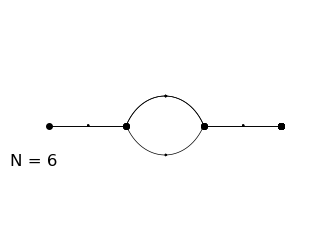

In [4]:
points, connections, count, diagrams = calculate_diagrams("phi4", 1, 1, 2)
print("counts:", list(count))
represent_order_diagram(points, connections, count, process=[1, 1], flavour=["simple", "simple"])

For $2 \to 2$ there are two diagrams at second order. At third order there are already nine.

order 2: 2 diagrams, counts [2, 18]
order 3: 9 diagrams, counts [4, 12, 12, 36, 36, 36, 72, 72, 72]


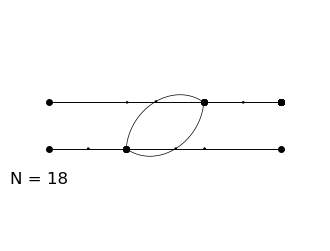

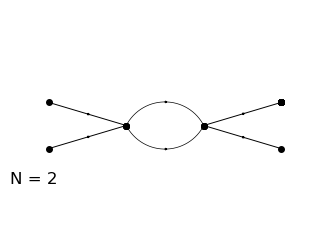

In [5]:
for order in (2, 3):
    points, connections, count, diagrams = calculate_diagrams("phi4", 2, 2, order)
    print(f"order {order}: {len(diagrams)} diagrams, counts {sorted(int(c) for c in count)}")

points, connections, count, diagrams = calculate_diagrams("phi4", 2, 2, 2)
represent_order_diagram(points, connections, count, process=[2, 2], flavour=["simple", "simple"])

## 3. Diagrams as Hamiltonian terms

Every diagram is a term of the effective Hamiltonian:

$$f_t \Big[\sum_\text{bracketings} \mathcal{B}_t^{(\dots)}\Big] \times \text{weight} \times (\text{product of initial terms}) \to \text{external operators}$$

- **$f_t$** is the form factor.
- **The coefficients $\mathcal{B}$** follow the notation of Głazek (2012), App. B. One coefficient appears for every way of building the product from products of two factors (a *bracketing*).
- **The weight** is the count multiplied by the normalisation of the terms. In $\phi^4$ the terms come from $\phi^4/4!$, so a term with $k$ creation and $l$ annihilation operators carries $1/(k!\,l!)$, and the weights reproduce the usual symmetry factors. For example, the sunset has $1/3!$.

External particles are numbered: outgoing ones first.

In [6]:
theory = get_theory("phi4")
print(expression_table(theory, generate_diagrams(theory, 2, 1, 1)))
print()
print(expression_table(theory, generate_diagrams(theory, 3, 2, 2)))

1. f_t B(123,0) 1/6 (H1_3 H1_2) -> a†1 a2

1. f_t [B(124,(234,0)) + B(134,(123,0))] 1/2 (H1_3 H1_1 H1_2) -> a†1 a†2 a3 a4
2. f_t [B(124,(234,0)) + B(134,(123,0))] 1/4 (H1_1 H1_3 H1_2) -> a†1 a†2 a3 a4
3. f_t [B(124,(234,0)) + B(134,(123,0))] 1/2 (H1_3 H1_1 H1_2) -> a†1 a†2 a3 a4
4. f_t [B(124,(234,0)) + B(134,(123,0))] 1/12 (H1_1 H1_3 H1_2) -> a†1 a†2 a3 a4
5. f_t [B(124,(234,0)) + B(134,(123,0))] 1/2 (H1_3 H1_1 H1_2) -> a†1 a†2 a3 a4
6. f_t [B(124,(234,0)) + B(134,(123,0))] 1/4 (H1_3 H1_2 H1_1) -> a†1 a†2 a3 a4
7. f_t [B(124,(234,0)) + B(134,(123,0))] 1/4 (H1_3 H1_1 H1_2) -> a†1 a†2 a3 a4
8. f_t [B(124,(234,0)) + B(134,(123,0))] 1/16 (H1_1 H1_1 H1_1) -> a†1 a†2 a3 a4
9. f_t [B(124,(234,0)) + B(134,(123,0))] 1/12 (H1_3 H1_2 H1_1) -> a†1 a†2 a3 a4


## 4. Products of terms before contraction

`term_products` lists which products of initial terms contribute to a process, with the total number of contractions of each. `products_table` prints them with their operators. With `mode="framework"`, `calculate_diagrams` draws these products with every leg open, before any contraction.

 216  H1_3 · H1_1 · H1_1 · H1_2  (a†aaa)(a†a†aa)(a†a†aa)(a†a†a†a)
  36  H1_3 · H1_2 · H1_3 · H1_2  (a†aaa)(a†a†a†a)(a†aaa)(a†a†a†a)
1080  H1_3 · H1_3 · H1_2 · H1_2  (a†aaa)(a†aaa)(a†a†a†a)(a†a†a†a)


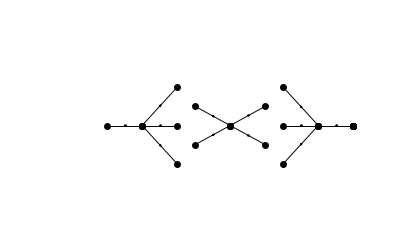

In [7]:
theory = get_theory("phi4")
print(products_table(theory, term_products(theory, 4, 1, 1)))

points, paths, _, products = calculate_diagrams("phi4", 1, 1, 3, mode="framework")
represent_order_diagram(points, paths, None, mode="framework", order=3, process=[1, 1])

## 5. Several types of particles: QCD

In QCD the particle types are, in this order: gluon, instantaneous line, quark and antiquark. A process is given as lists with the number of particles of each type. For example, `[1, 0, 0, 0]` is one gluon and `[0, 0, 1, 0]` is one quark.

At second order:
- the gluon self-energy has a gluon loop and a quark loop;
- the quark self-energy has one diagram.

In the drawings, quarks are blue and antiquarks red.

gluon -> gluon
1. f_t B(123,0) 2 (H1_2 H1_1) -> a†1 a2
2. f_t B(123,0) 1 (H1_8 H1_7) -> a†1 a2


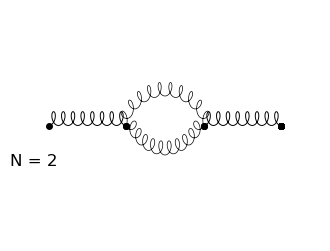

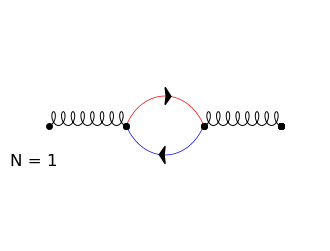

quark -> quark
1. f_t B(123,0) 1 (H1_4 H1_3) -> b†1 b2


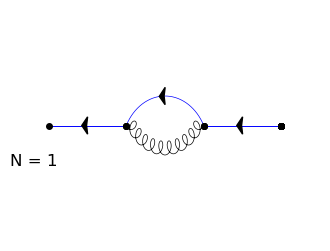

In [8]:
theory = get_theory("qcd")
for label, n_in, n_out in [("gluon -> gluon", [1, 0, 0, 0], [1, 0, 0, 0]), ("quark -> quark", [0, 0, 1, 0], [0, 0, 1, 0])]:
    points, connections, count, diagrams = calculate_diagrams("qcd", n_in, n_out, 2)
    print(label)
    print(expression_table(theory, diagrams))
    represent_order_diagram(points, connections, count, process=[n_in, n_out])

At third order, a quark emitting a gluon already has 18 diagrams. Here are the first four.

18 diagrams


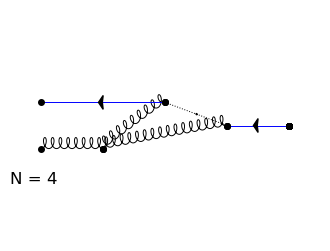

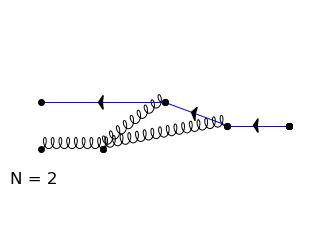

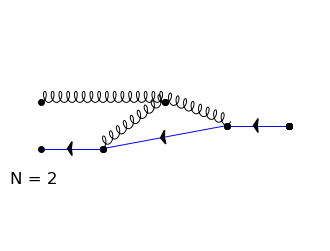

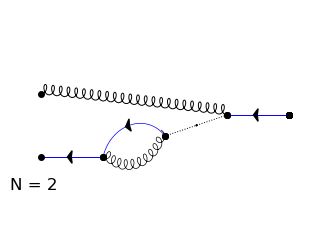

In [9]:
points, connections, count, diagrams = calculate_diagrams("qcd", [0, 0, 1, 0], [1, 0, 1, 0], 3)
print(len(diagrams), "diagrams")
represent_order_diagram(points[:4], connections[:4], count[:4], process=[[0, 0, 1, 0], [1, 0, 1, 0]])

## 6. Counterterms

With `counterterms=True`, the initial Hamiltonian also gets:
- a mass counterterm for every type of particle;
- a coupling counterterm for every first-order term.

Each is added at every order at which the theory has a loop correction to it. Counterterm vertices are drawn with a star.

For the three-gluon vertex at third order, this gives the 10 diagrams of Fig. 7 of Gómez-Rocha and Głazek, PRD 92, 065005 (2015):
- the gluon triangle, (a);
- the triangle with an instantaneous line, (b) and (c);
- loops on the external legs, (d), (e), (g) and (h);
- the mass counterterm on a leg, (f) and (i);
- the vertex counterterm, (j).

counterterms: ['CT2_mass_gluon', 'CT3_H1_1', 'CT3_H1_2']
10 diagrams, 3 with a counterterm
 1. f_t 1 (CT3_H1_1) -> a†1 a†2 a3
 2. f_t B(123,0) 2 (CT2_mass_gluon H1_1) -> a†1 a†2 a3
 3. f_t B(123,0) 1 (H1_1 CT2_mass_gluon) -> a†1 a†2 a3
 4. f_t [B(124,(234,0)) + B(134,(123,0))] 8 (H1_2 H1_1 H1_1) -> a†1 a†2 a3
 5. f_t B(123,0) [4 (H1_2 H2_1) + 4 (H1_2 H2_2) + 4 (H1_2 H2_3)] -> a†1 a†2 a3
 6. f_t [B(124,(234,0)) + B(134,(123,0))] 2 (H1_1 H1_2 H1_1) -> a†1 a†2 a3
 7. f_t [B(124,(234,0)) + B(134,(123,0))] 4 (H1_2 H1_1 H1_1) -> a†1 a†2 a3
 8. f_t B(123,0) [2 (H1_2 H2_1) + 2 (H1_2 H2_2) + 2 (H1_2 H2_3)] -> a†1 a†2 a3
 9. f_t B(123,0) [2 (H2_5 H1_1) + 2 (H2_6 H1_1) + 2 (H2_7 H1_1) + 2 (H2_8 H1_1)] -> a†1 a†2 a3
10. f_t B(123,0) 2 (H2_4 H1_1) -> a†1 a†2 a3


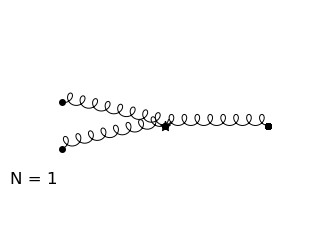

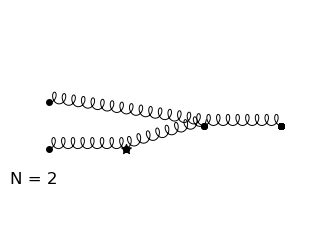

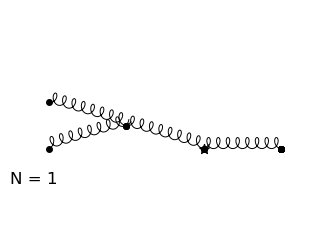

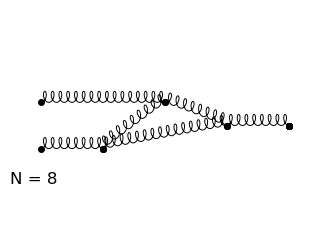

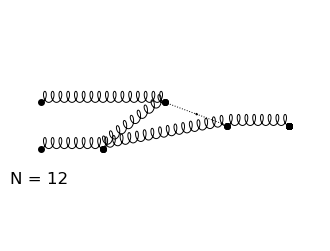

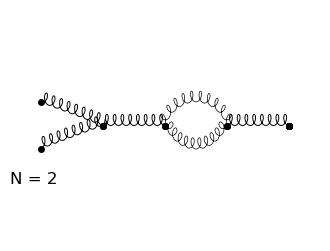

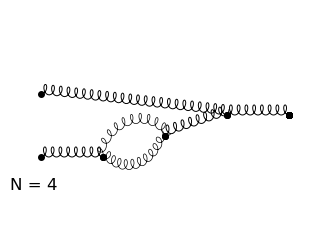

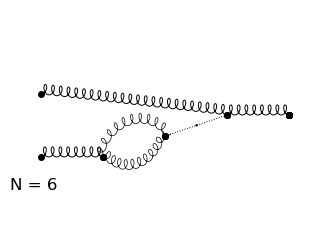

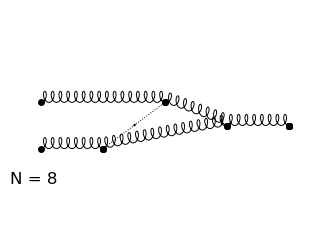

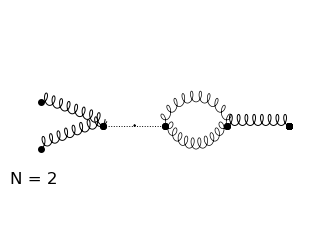

In [10]:
theory = get_theory("qcd_gluons", counterterms=True, max_order=3)
print("counterterms:", [term.name for term in theory.terms if term.counterterm])

points, connections, count, diagrams = calculate_diagrams("qcd_gluons", [1, 0], [2, 0], 3, counterterms=True)
print(len(diagrams), "diagrams,", sum(1 for d in diagrams if d.counterterms), "with a counterterm")
print(expression_table(theory, diagrams))
represent_order_diagram(points, connections, count, process=[[1, 0], [2, 0]], flavour=["loopy", "simple"])

## 7. Inside a diagram

The diagram objects returned by `generate_diagrams`, or as the fourth value of `calculate_diagrams`, contain everything about a diagram. Here is the gluon triangle from above:

In [11]:
triangle = next(d for d in diagrams
                if {(a, b) for _, a, b, _ in d.lines} == {(0, 1), (0, 2), (1, 2)} and all(t == 0 for t, *_ in d.lines))

print("vertices:            ", triangle.n_vertices)
print("lines (type, a, b, n):", triangle.lines)
print("external lines:      ", external_legs(triangle))
print("operator:            ", diagram_operator(theory, triangle))
print("products of terms:   ", {tuple(theory.terms[i].name for i in s): c for s, c in triangle.products.items()})
print("bracketings:         ", triangle.bracketings)
print("count and weight:    ", triangle.count, triangle.weight)

vertices:             3
lines (type, a, b, n): ((0, 0, 1, 1), (0, 0, 2, 1), (0, 1, 2, 1))
external lines:       [(1, 0, 0, 'out'), (2, 1, 0, 'out'), (3, 2, 0, 'in')]
operator:             a†1 a†2 a3
products of terms:    {('H1_2', 'H1_1', 'H1_1'): 8}
bracketings:          ((0, (1, 2)), ((0, 1), 2))
count and weight:     8 8


## 8. LaTeX output

`write_latex` writes a document with every diagram drawn with TikZ-Feynman and its expression. You can also include the table of products. Compile it with `pdflatex`; the `tikz-feynman` package is needed.

In [12]:
write_latex("output/three_gluon_vertex.tex", theory, diagrams, title="Three-gluon vertex at third order",
            products=term_products(theory, 3, [1, 0], [2, 0]))
print("written output/three_gluon_vertex.tex, compile it with: cd output && pdflatex three_gluon_vertex.tex")

written output/three_gluon_vertex.tex, compile it with: cd output && pdflatex three_gluon_vertex.tex


## 9. Large orders

For large orders, two options of `generate_diagrams`, `term_products` and `calculate_diagrams` help:
- **`workers`** splits the work among processes. `workers=None` uses one per CPU.
- **`cache`** keeps the result on disk. The result is recomputed automatically when the theory, the process or the code changes.

Below, $\phi^4$ $2 \to 2$ at seventh order has more than 100 000 diagrams. The first run is only slow the first time the notebook runs; after that both runs read from the cache.

In [13]:
theory = get_theory("phi4")

start = time.time()
diagrams = generate_diagrams(theory, 7, 2, 2, workers=None, cache="output/cache")
print(f"first run: {len(diagrams)} diagrams in {time.time() - start:.1f} s")

start = time.time()
diagrams = generate_diagrams(theory, 7, 2, 2, cache="output/cache")
print(f"second run, from the cache: {time.time() - start:.1f} s")

first run: 121419 diagrams in 8.4 s
second run, from the cache: 2.3 s
